k = 2, Inertia = 222.36, Silhouette Score = 0.5818
k = 3, Inertia = 139.82, Silhouette Score = 0.4599
k = 4, Inertia = 114.09, Silhouette Score = 0.3869
k = 5, Inertia = 90.93, Silhouette Score = 0.3459
k = 6, Inertia = 81.54, Silhouette Score = 0.3171
k = 7, Inertia = 72.63, Silhouette Score = 0.3202
k = 8, Inertia = 62.54, Silhouette Score = 0.3387
k = 9, Inertia = 55.12, Silhouette Score = 0.3424
k = 10, Inertia = 47.39, Silhouette Score = 0.3518


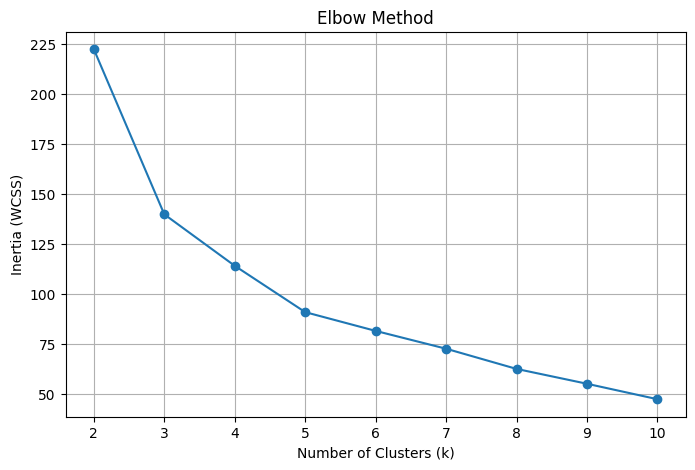

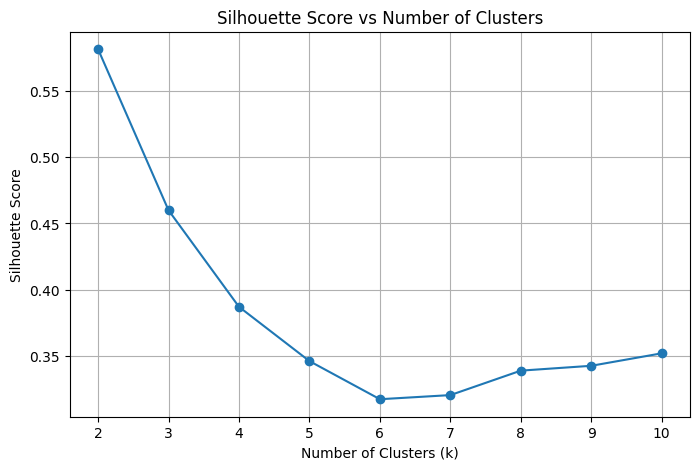


Best k according to Silhouette Score: 2


In [1]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Load Dataset
iris = load_iris()
X = iris.data

# 2. Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Store results
inertia_values = []
silhouette_values = []
k_values = range(2, 11)

# 4. Fit K-Means for k = 2 to 10
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    # Elbow Method
    inertia_values.append(kmeans.inertia_)

    # Silhouette Score
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

    print(f"k = {k}, Inertia = {kmeans.inertia_:.2f}, "
          f"Silhouette Score = {score:.4f}")

# 5. Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# 6. Plot Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs Number of Clusters")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# 7. Find k with highest silhouette score
best_k = list(k_values)[silhouette_values.index(max(silhouette_values))]

print("\nBest k according to Silhouette Score:", best_k)
